# Synthetic ULTRASAT Field Ranking

This notebook exercises ULTRApipe's field-scoring function on a small, explicitly synthetic target list. It uses the repository's tracked saturation and limiting-magnitude tables, assumes zero reddening so the run is offline, and compares three candidate field centers. The bar chart and hoverable HTML show the weights returned by `cost_function()`.

The targets are toy inputs, not an exoplanet catalog or a real pointing recommendation. The full-sky `cost_function_map()` uses the remote Bayestar dust service and is deliberately not run here.

In [5]:
from pathlib import Path
import os
import sys
import warnings

warnings.filterwarnings(
    "ignore",
    message="Unable to find acceptable character detection dependency.*",
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

search_roots = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
repository_root = next(
    candidate for candidate in search_roots
    if (candidate / "utils.py").is_file()
    and (candidate / "systematics" / "SatMag.csv").is_file()
)
for import_root in (
    repository_root,
    repository_root.parent.parent / "tansudaylan" / "tdpy",
):
    if str(import_root) not in sys.path:
        sys.path.insert(0, str(import_root))

from utils import cost_function
from paths import get_visuals_path
from tdpy.verbosity import print

systematics_directory = repository_root / "systematics"
saturation_path = Path(os.path.relpath(
    systematics_directory / "SatMag.csv", Path.cwd()
))
limiting_path = Path(os.path.relpath(
    systematics_directory / "LimMag.csv", Path.cwd()
))
visuals_directory = get_visuals_path().parent / "examples" / "visuals"
visuals_directory.mkdir(parents=True, exist_ok=True)

In [6]:
target_ra_deg = np.array([1.0, 4.0, 118.0, 122.0, 242.0, 250.0])  # [deg]
target_dec_deg = np.array([1.0, -2.0, 0.0, 3.0, -1.0, 4.0])  # [deg]
target_ab_magnitude = np.array([15.0, 20.0, 16.0, 13.5, 20.0, 24.0])  # [mag]
target_temperature_k = np.array([9600.0, 5800.0, 8750.0, 6050.0, 5240.0, 4000.0])  # [K]
target_weights = np.array([1.0, 1.0, 1.5, 1.0, 2.0, 1.0])
data_weights = np.ones(target_ra_deg.size)
reddening = np.zeros(target_ra_deg.size)  # [mag], toy no-extinction assumption
field_names = ["Synthetic A", "Synthetic B", "Synthetic C"]
field_centers_deg = [(0.0, 0.0), (120.0, 0.0), (240.0, 0.0)]  # [(RA, Dec), deg]
field_radius_deg = 7.0  # [deg]

score_rows = []
for field_name, (center_ra_deg, center_dec_deg) in zip(field_names, field_centers_deg):
    score = cost_function(
        center_ra_deg,
        center_dec_deg,
        field_radius_deg,
        target_ra_deg,
        target_dec_deg,
        target_ab_magnitude,
        target_temperature_k,
        saturation_path,
        limiting_path,
        reddening=reddening,
        target_weight_list=target_weights,
        data_weight_list=data_weights,
    )
    score_rows.append({"field": field_name, "ra_deg": center_ra_deg, "dec_deg": center_dec_deg, "toy_score": score})

field_scores = pd.DataFrame(score_rows)
display(field_scores)

,field,ra_deg,dec_deg,toy_score
0,Synthetic A,0.0,0.0,0.75
1,Synthetic B,120.0,0.0,0.75
2,Synthetic C,240.0,0.0,0.50


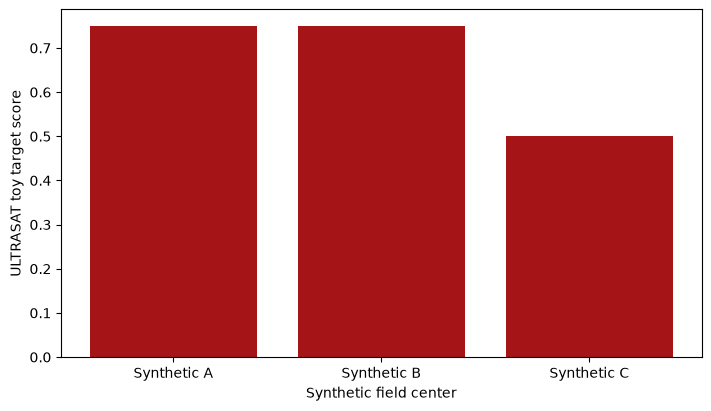

In [7]:
static_figure, static_axis = plt.subplots(figsize=(7.0, 4.0), constrained_layout=True)
static_figure.patch.set_facecolor("white")
static_axis.set_facecolor("white")
static_axis.bar(field_scores["field"], field_scores["toy_score"], color="#A51417")
static_axis.set_ylabel("ULTRASAT toy target score")
static_axis.set_xlabel("Synthetic field center")
static_axis.grid(False)
static_path = visuals_directory / "ultrapipe_synthetic_field_scores.png"
print(f"Writing to visuals/{static_path.name}...")
static_figure.savefig(static_path, dpi=300, bbox_inches="tight", facecolor="white")
display(static_figure)
plt.close(static_figure)

from bokeh.models import ColumnDataSource, HoverTool
from bokeh.plotting import figure as bokeh_figure
from IPython.display import IFrame
from tdpy.plotting import save_bokeh_html

interactive_figure = bokeh_figure(
    title="Synthetic ULTRASAT field scores",
    width=700,
    height=420,
    x_range=field_names,
    sizing_mode="stretch_width",
    x_axis_label="Synthetic field center",
    y_axis_label="ULTRASAT toy target score",
    tools="pan,wheel_zoom,box_zoom,reset,save",
)
source = ColumnDataSource(field_scores)
renderer = interactive_figure.vbar(
    x="field",
    top="toy_score",
    width=0.6,
    source=source,
    color="#16697A",
)
interactive_figure.add_tools(HoverTool(
    renderers=[renderer],
    tooltips=[
        ("Field", "@field"),
        ("Center RA [deg]", "@ra_deg{0.0}"),
        ("Center Dec [deg]", "@dec_deg{0.0}"),
        ("Toy score", "@toy_score{0.00}"),
    ],
))
interactive_figure.grid.visible = False
interactive_path = visuals_directory / "ultrapipe_synthetic_field_scores.html"
interactive_relative_path = Path(os.path.relpath(interactive_path, Path.cwd()))
print(f"Writing to visuals/{interactive_path.name}...")
save_bokeh_html(
    interactive_figure,
    interactive_relative_path,
    title="ULTRApipe synthetic field ranking",
    typeplotback="white",
)
display(IFrame(src=str(interactive_relative_path), width="100%", height=440))